<a href="https://colab.research.google.com/github/pontonganronald-byte/pontongan_ai_iris_labactivity1/blob/main/Pontongan_lab_exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_curve, roc_auc_score, confusion_matrix)

In [33]:
df.columns = df.columns.str.strip()
df = df.rename(columns={c: "Churn" for c in df.columns if c.lower() == "churn"})
df["area code"] = df["area code"].astype(str)
print(df.columns.tolist())

['state', 'account length', 'area code', 'phone number', 'international plan', 'voice mail plan', 'number vmail messages', 'total day minutes', 'total day calls', 'total day charge', 'total eve minutes', 'total eve calls', 'total eve charge', 'total night minutes', 'total night calls', 'total night charge', 'total intl minutes', 'total intl calls', 'total intl charge', 'customer service calls', 'Churn']


In [34]:
df = pd.read_csv("telecom_churn (1).csv")
print(df.shape)
df.head()

(3333, 21)


,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [35]:
df.columns = df.columns.str.strip()
df = df.rename(columns={c: "Churn" for c in df.columns if c.lower() == "churn"})
df["area code"] = df["area code"].astype(str)
print(df.columns.tolist())

['state', 'account length', 'area code', 'phone number', 'international plan', 'voice mail plan', 'number vmail messages', 'total day minutes', 'total day calls', 'total day charge', 'total eve minutes', 'total eve calls', 'total eve charge', 'total night minutes', 'total night calls', 'total night charge', 'total intl minutes', 'total intl calls', 'total intl charge', 'customer service calls', 'Churn']


In [36]:
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nTarget distribution:")
print(df["Churn"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   object 
 1   account length          3333 non-null   int64  
 2   area code               3333 non-null   object 
 3   phone number            3333 non-null   object 
 4   international plan      3333 non-null   object 
 5   voice mail plan         3333 non-null   object 
 6   number vmail messages   3333 non-null   int64  
 7   total day minutes       3333 non-null   float64
 8   total day calls         3333 non-null   int64  
 9   total day charge        3333 non-null   float64
 10  total eve minutes       3333 non-null   float64
 11  total eve calls         3333 non-null   int64  
 12  total eve charge        3333 non-null   float64
 13  total night minutes     3333 non-null   float64
 14  total night calls       3333 non-null   

In [37]:
# Clean the target: convert True/False (or Yes/No, 1/0) into 1/0
df["Churn"] = (df["Churn"].astype(str).str.strip().str.lower()
               .map({"true": 1, "false": 0, "yes": 1, "no": 0, "1": 1, "0": 0}))
df = df.dropna(subset=["Churn"])      # drop rows where the target is missing
df["Churn"] = df["Churn"].astype(int)

# Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Drop identifier-like columns (e.g., customer ID, phone number) if present
id_cols = [c for c in X.columns if "id" == c.lower() or "phone" in c.lower() or "customerid" in c.lower()]
X = X.drop(columns=id_cols)
print("Dropped ID columns:", id_cols)

# Identify numeric vs. categorical columns
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

Dropped ID columns: ['phone number']
Numeric: ['account length', 'number vmail messages', 'total day minutes', 'total day calls', 'total day charge', 'total eve minutes', 'total eve calls', 'total eve charge', 'total night minutes', 'total night calls', 'total night charge', 'total intl minutes', 'total intl calls', 'total intl charge', 'customer service calls']
Categorical: ['state', 'area code', 'international plan', 'voice mail plan']


In [46]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols)
])

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train churn ratio:", round(y_train.mean(), 4))
print("Test churn ratio: ", round(y_test.mean(), 4))

Train: (2666, 19) Test: (667, 19)
Train churn ratio: 0.1448
Test churn ratio:  0.1454


In [40]:
models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocessor),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Decision Tree": Pipeline([
        ("prep", preprocessor),
        ("model", DecisionTreeClassifier(max_depth=5, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("model", RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))
    ]),
}

# Train all three models
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print(f"{name} trained.")

Logistic Regression trained.
Decision Tree trained.
Random Forest trained.


In [41]:
preds, probs = {}, {}
for name, pipe in models.items():
    preds[name] = pipe.predict(X_test)                 # predicted class (0/1 -> False/True)
    probs[name] = pipe.predict_proba(X_test)[:, 1]     # probability of churn

pred_df = pd.DataFrame({"Actual": y_test.values})
for name in models:
    pred_df[f"{name} (class)"] = preds[name]
    pred_df[f"{name} (prob)"] = probs[name].round(4)
pred_df.head(10)

,Actual,Logistic Regression (class),Logistic Regression (prob),Decision Tree (class),Decision Tree (prob),Random Forest (class),Random Forest (prob)
0,1,0,0.1808,1,1.0000,0,0.4347
1,0,0,0.1249,0,0.0241,0,0.0901
2,0,0,0.1118,0,0.0368,0,0.2098
3,0,0,0.1318,0,0.0241,0,0.1052
4,0,0,0.3595,0,0.0241,0,0.0992
5,0,0,0.0550,0,0.0241,0,0.0769
6,0,0,0.2805,0,0.0241,0,0.1120
7,0,0,0.1141,0,0.0241,0,0.0946
8,0,0,0.0337,0,0.0241,0,0.1072
9,0,0,0.1029,0,0.0241,0,0.0948


In [42]:
results = {}
for name in models:
    results[name] = {
        "Accuracy":  accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name], zero_division=0),
        "Recall":    recall_score(y_test, preds[name]),
        "F1-Score":  f1_score(y_test, preds[name]),
    }

summary = pd.DataFrame(results)
summary.index.name = "Metric"
summary.round(4)

,Logistic Regression,Decision Tree,Random Forest
Metric,,,
Accuracy,0.8591,0.9175,0.8846
Precision,0.5333,0.7625,0.9167
Recall,0.2474,0.6289,0.2268
F1-Score,0.3380,0.6893,0.3636


In [43]:
for name in models:
    tn, fp, fn, tp = confusion_matrix(y_test, preds[name]).ravel()
    print(f"{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Logistic Regression: TN=549, FP=21, FN=73, TP=24
Decision Tree: TN=551, FP=19, FN=36, TP=61
Random Forest: TN=568, FP=2, FN=75, TP=22


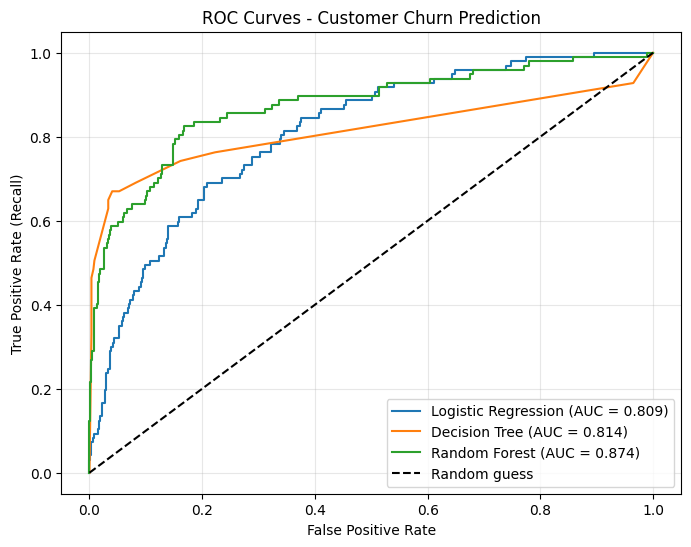

In [44]:
plt.figure(figsize=(8, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    auc = roc_auc_score(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves - Customer Churn Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()